# BQ06 — Khách hàng rời bỏ tập trung ở nhóm tuổi thiết bị nào?

**Câu hỏi nghiệp vụ:** Trong toàn bộ khách hàng đã rời bỏ dịch vụ, họ tập trung ở những nhóm tuổi thiết bị nào? Nhóm nào đóng góp số khách rời bỏ cao hơn mức kỳ vọng theo quy mô khách hàng của chính nhóm đó?

**Mục tiêu ra quyết định:** tìm nhóm thiết bị đáng ưu tiên đưa sang BQ07 và cân nhắc thử nghiệm rà soát hoặc nâng cấp thiết bị.

## Chỉ số chính

Notebook không lấy `số khách rời bỏ / tổng số khách trong nhóm` làm chỉ số chính.

Thay vào đó sử dụng:

\[
Tỷ\ trọng\ khách\ hàng_i = \frac{n_i}{N}
\]

\[
Tỷ\ trọng\ khách\ rời\ bỏ_i = \frac{Churn_i}{Tổng\ số\ churn}
\]

\[
Chỉ\ số\ tập\ trung_i =
\frac{Tỷ\ trọng\ khách\ rời\ bỏ_i}
{Tỷ\ trọng\ khách\ hàng_i}
\]

Cách đọc:

- **Tỷ trọng khách hàng:** nhóm này chiếm bao nhiêu trong toàn bộ khách hàng.
- **Tỷ trọng khách rời bỏ:** nhóm này chiếm bao nhiêu trong toàn bộ khách đã rời bỏ.
- **Chỉ số tập trung > 1:** nhóm đóng góp churn nhiều hơn quy mô của chính nó.
- **Chỉ số tập trung ≈ 1:** churn tương xứng với quy mô nhóm.
- **Chỉ số tập trung < 1:** nhóm đóng góp churn thấp hơn quy mô nhóm.

> Chỉ số tập trung dùng để mô tả mức độ tập trung churn, không chứng minh tuổi thiết bị là nguyên nhân gây churn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "figure.figsize": (14, 8),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})


## 1. Đọc dữ liệu và chuẩn hóa biến mục tiêu

In [2]:
DATA_PATH = "../data/cell2cell_complete_cases.csv"

df = pd.read_csv(DATA_PATH)

required_cols = [
    "CurrentEquipmentDays",
    "MonthsInService",
    "Churn"
]

missing_cols = [c for c in required_cols if c not in df.columns]
assert not missing_cols, f"Thiếu cột bắt buộc: {missing_cols}"

print("Kích thước dữ liệu:", df.shape)
display(df[required_cols].head())


Kích thước dữ liệu: (49752, 58)


,CurrentEquipmentDays,MonthsInService,Churn
0,361.0,61,Yes
1,1504.0,58,Yes
2,1812.0,60,No
3,458.0,59,No
4,852.0,53,Yes


In [3]:
print("Các giá trị của biến Churn:", df["Churn"].dropna().unique())

if df["Churn"].dtype == "object":
    churn_map = {
        "Yes": 1, "No": 0,
        "yes": 1, "no": 0,
        "Y": 1, "N": 0,
        "True": 1, "False": 0,
        "true": 1, "false": 0
    }
    df["Churn_bin"] = df["Churn"].map(churn_map)
else:
    df["Churn_bin"] = pd.to_numeric(
        df["Churn"],
        errors="coerce"
    )

bq06 = df[
    [
        "CurrentEquipmentDays",
        "MonthsInService",
        "Churn_bin"
    ]
].copy()

bq06["CurrentEquipmentDays"] = pd.to_numeric(
    bq06["CurrentEquipmentDays"],
    errors="coerce"
)

bq06["MonthsInService"] = pd.to_numeric(
    bq06["MonthsInService"],
    errors="coerce"
)

display(bq06.head())


Các giá trị của biến Churn: ['Yes' 'No']


,CurrentEquipmentDays,MonthsInService,Churn_bin
0,361.0,61,1
1,1504.0,58,1
2,1812.0,60,0
3,458.0,59,0
4,852.0,53,1


## 2. Kiểm tra chất lượng dữ liệu `CurrentEquipmentDays`

Không tự động sửa tuổi thiết bị âm hoặc các giá trị cực lớn.

- Thiếu dữ liệu: loại khỏi tập phân tích BQ06 và báo số lượng.
- `CurrentEquipmentDays < 0`: xem là không hợp lệ cho phân tích tuổi thiết bị.
- Giá trị rất lớn: vẫn giữ trong phân tích chính; kiểm tra độ nhạy bằng cách thay đổi độ rộng khoảng tuổi thiết bị.

In [4]:
qa = pd.DataFrame({
    "Chỉ số": [
        "Tổng số dòng",
        "Thiếu số ngày tuổi thiết bị",
        "Thiếu thời gian sử dụng dịch vụ",
        "Giá trị Churn không hợp lệ",
        "Tuổi thiết bị âm",
        "Tuổi thiết bị bằng 0"
    ],
    "Số lượng": [
        len(bq06),
        int(bq06["CurrentEquipmentDays"].isna().sum()),
        int(bq06["MonthsInService"].isna().sum()),
        int(bq06["Churn_bin"].isna().sum()),
        int((bq06["CurrentEquipmentDays"] < 0).sum()),
        int((bq06["CurrentEquipmentDays"] == 0).sum())
    ]
})

display(qa)

display(
    bq06["CurrentEquipmentDays"]
    .describe(
        percentiles=[
            0.01, 0.05, 0.25, 0.50,
            0.75, 0.95, 0.99
        ]
    )
    .to_frame("CurrentEquipmentDays")
)


,Chỉ số,Số lượng
0,Tổng số dòng,49752
1,Thiếu số ngày tuổi thiết bị,0
2,Thiếu thời gian sử dụng dịch vụ,0
3,Giá trị Churn không hợp lệ,0
4,Tuổi thiết bị âm,74
5,Tuổi thiết bị bằng 0,22


,CurrentEquipmentDays
count,49752.000000
mean,380.020843
std,252.290072
min,-5.000000
1%,7.000000
5%,42.000000
25%,205.000000
50%,330.000000
75%,515.000000
95%,864.000000


In [5]:
bq06_valid = (
    bq06
    .dropna(
        subset=[
            "CurrentEquipmentDays",
            "MonthsInService",
            "Churn_bin"
        ]
    )
    .copy()
)

negative_mask = bq06_valid["CurrentEquipmentDays"] < 0

print(
    "Loại khỏi BQ06 vì tuổi thiết bị âm:",
    int(negative_mask.sum())
)

bq06_valid = (
    bq06_valid
    .loc[~negative_mask]
    .copy()
)

bq06_valid["Churn_bin"] = (
    bq06_valid["Churn_bin"]
    .astype(int)
)

AVG_DAYS_PER_MONTH = 365.25 / 12

bq06_valid["EquipmentAgeMonths"] = (
    bq06_valid["CurrentEquipmentDays"]
    / AVG_DAYS_PER_MONTH
)

TOTAL_CUSTOMERS = len(bq06_valid)
TOTAL_CHURN = int(bq06_valid["Churn_bin"].sum())

print(f"Số khách hàng hợp lệ : {TOTAL_CUSTOMERS:,}")
print(f"Tổng khách rời bỏ     : {TOTAL_CHURN:,}")

assert TOTAL_CUSTOMERS > 0
assert TOTAL_CHURN > 0


Loại khỏi BQ06 vì tuổi thiết bị âm: 74
Số khách hàng hợp lệ : 49,678
Tổng khách rời bỏ     : 14,231


## 3. Biểu đồ phân phối tuổi thiết bị theo trạng thái rời bỏ

- Trục X: tuổi thiết bị hiện tại, quy đổi sang tháng.
- Trục Y: số khách hàng.
- **Màu đỏ:** khách hàng rời bỏ.
- **Màu xám:** khách hàng không rời bỏ.
- Độ rộng mỗi khoảng mặc định: **6 tháng**.

Biểu đồ này cho biết **quy mô churn tập trung ở vùng tuổi thiết bị nào**. Phần sau mới kiểm tra xem vùng nào đóng góp churn vượt quá tỷ trọng khách hàng của chính nó.

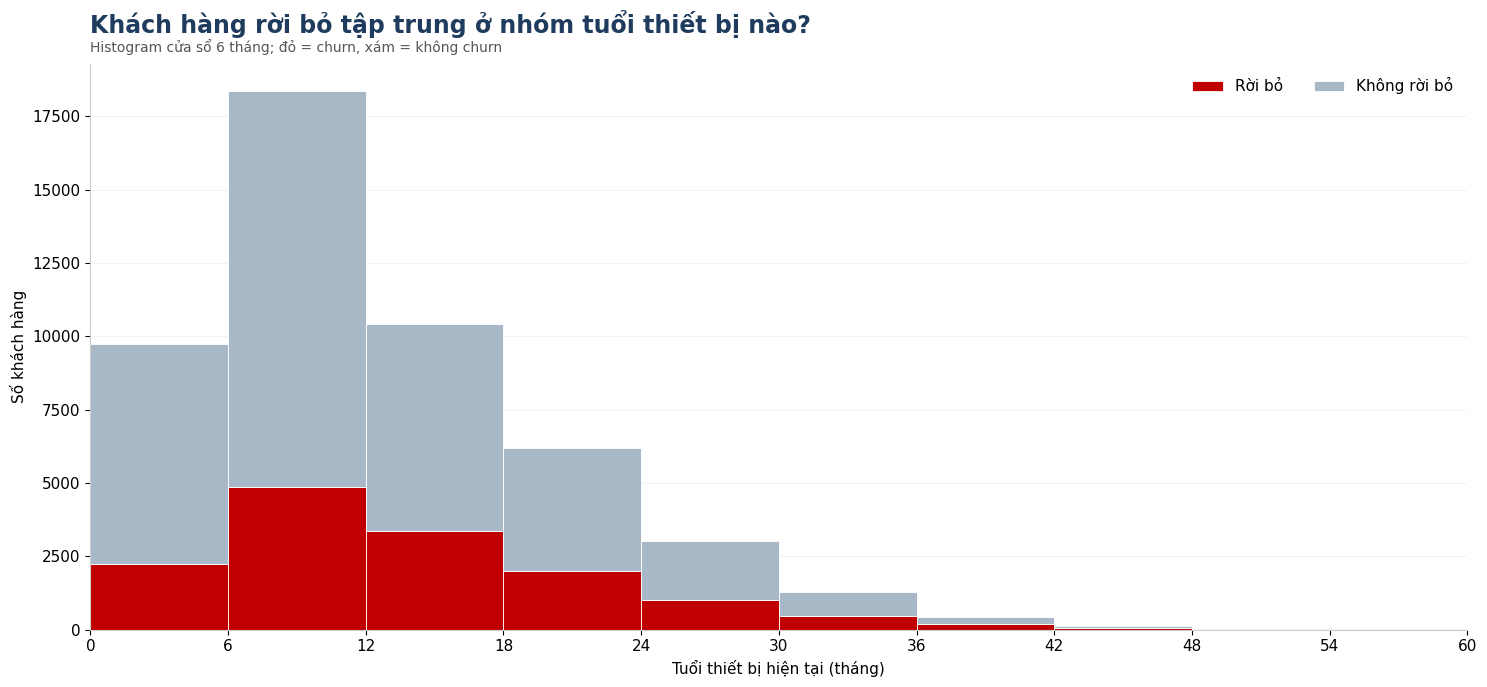

In [6]:
BIN_WIDTH_MONTHS = 6

max_age = float(bq06_valid["EquipmentAgeMonths"].max())

hist_bins = np.arange(
    0,
    np.ceil(max_age / BIN_WIDTH_MONTHS) * BIN_WIDTH_MONTHS
    + BIN_WIDTH_MONTHS,
    BIN_WIDTH_MONTHS
)

churn_age = bq06_valid.loc[
    bq06_valid["Churn_bin"] == 1,
    "EquipmentAgeMonths"
]

non_churn_age = bq06_valid.loc[
    bq06_valid["Churn_bin"] == 0,
    "EquipmentAgeMonths"
]

fig, ax = plt.subplots(figsize=(15, 7))

ax.hist(
    [churn_age, non_churn_age],
    bins=hist_bins,
    stacked=True,
    color=["#C00000", "#A9B8C7"],
    label=["Rời bỏ", "Không rời bỏ"],
    edgecolor="white",
    linewidth=0.6
)

ax.set_title(
    "Khách hàng rời bỏ tập trung ở nhóm tuổi thiết bị nào?",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#1F3B5D",
    pad=22
)

ax.text(
    0,
    1.02,
    (
        f"Histogram cửa sổ {BIN_WIDTH_MONTHS} tháng; "
        "đỏ = churn, xám = không churn"
    ),
    transform=ax.transAxes,
    fontsize=10,
    color="#555555"
)

ax.set_xlabel("Tuổi thiết bị hiện tại (tháng)")
ax.set_ylabel("Số khách hàng")

ax.set_xlim(0, hist_bins[-1])
ax.set_ylim(bottom=0)
ax.margins(x=0, y=0)

ax.set_xticks(
    np.arange(
        0,
        hist_bins[-1] + 1,
        BIN_WIDTH_MONTHS
    )
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(
    frameon=False,
    ncol=2,
    loc="upper right"
)

plt.tight_layout()
plt.show()


## 4. Tạo bảng mức tập trung churn theo khoảng 6 tháng

Đây là bảng chỉ số chính của BQ06.

Mỗi nhóm tuổi thiết bị được tính:

- số khách hàng;
- số khách rời bỏ;
- tỷ trọng khách hàng;
- tỷ trọng khách rời bỏ;
- phần churn vượt quy mô;
- chỉ số tập trung churn.

Không dùng riêng tỷ lệ churn trong nhóm để đưa ra quyết định.

In [7]:
def make_fixed_width_summary(data, width_months=6):
    max_age = float(data["EquipmentAgeMonths"].max())

    edges = np.arange(
        0,
        np.ceil(max_age / width_months) * width_months
        + width_months,
        width_months
    )

    labels = [
        f"{int(edges[i])}–{int(edges[i+1]-1)}"
        for i in range(len(edges) - 1)
    ]

    tmp = data.copy()

    tmp["EquipmentAgeBand"] = pd.cut(
        tmp["EquipmentAgeMonths"],
        bins=edges,
        labels=labels,
        right=False,
        include_lowest=True,
        ordered=True
    )

    summary = (
        tmp
        .groupby(
            "EquipmentAgeBand",
            observed=False
        )
        .agg(
            n=("Churn_bin", "size"),
            churn_count=("Churn_bin", "sum")
        )
        .reset_index()
    )

    summary = summary.loc[
        summary["n"] > 0
    ].copy()

    summary["customer_share"] = (
        summary["n"]
        / summary["n"].sum()
    )

    summary["churn_share"] = (
        summary["churn_count"]
        / summary["churn_count"].sum()
    )

    summary["excess_churn_share_pp"] = (
        summary["churn_share"]
        - summary["customer_share"]
    ) * 100

    summary["concentration_index"] = (
        summary["churn_share"]
        / summary["customer_share"]
    )

    return tmp, summary


bq06_6m, concentration_6m = make_fixed_width_summary(
    bq06_valid,
    width_months=6
)

display(concentration_6m)


,EquipmentAgeBand,n,churn_count,customer_share,churn_share,excess_churn_share_pp,concentration_index
0,0–5,9721,2230,0.195680,0.156700,-3.898002,0.800797
1,6–11,18377,4872,0.369922,0.342351,-2.757109,0.925468
2,12–17,10410,3352,0.209549,0.235542,2.599263,1.124041
3,18–23,6199,1998,0.124784,0.140398,1.561412,1.125130
4,24–29,3007,1021,0.060530,0.071745,1.121497,1.185280
5,30–35,1300,483,0.026169,0.033940,0.777146,1.296978
6,36–41,445,189,0.008958,0.013281,0.432318,1.482622
7,42–47,143,62,0.002879,0.004357,0.147815,1.513507
8,48–53,57,22,0.001147,0.001546,0.039853,1.347338
9,54–59,19,2,0.000382,0.000141,-0.024192,0.367456


In [8]:
display_table = concentration_6m.copy()

display_table["customer_share"] = (
    display_table["customer_share"] * 100
).round(2)

display_table["churn_share"] = (
    display_table["churn_share"] * 100
).round(2)

display_table["excess_churn_share_pp"] = (
    display_table["excess_churn_share_pp"]
).round(2)

display_table["concentration_index"] = (
    display_table["concentration_index"]
).round(2)

display(
    display_table[
        [
            "EquipmentAgeBand",
            "n",
            "churn_count",
            "customer_share",
            "churn_share",
            "excess_churn_share_pp",
            "concentration_index"
        ]
    ].rename(
        columns={
            "EquipmentAgeBand": "Tuổi thiết bị (tháng)",
            "n": "Số khách",
            "churn_count": "Số khách rời bỏ",
            "customer_share": "Tỷ trọng khách hàng (%)",
            "churn_share": "Tỷ trọng khách rời bỏ (%)",
            "excess_churn_share_pp": "Phần churn vượt quy mô (điểm %)",
            "concentration_index": "Chỉ số tập trung churn"
        }
    )
)


,Tuổi thiết bị (tháng),Số khách,Số khách rời bỏ,Tỷ trọng khách hàng (%),Tỷ trọng khách rời bỏ (%),Phần churn vượt quy mô (điểm %),Chỉ số tập trung churn
0,0–5,9721,2230,19.57,15.67,-3.90,0.80
1,6–11,18377,4872,36.99,34.24,-2.76,0.93
2,12–17,10410,3352,20.95,23.55,2.60,1.12
3,18–23,6199,1998,12.48,14.04,1.56,1.13
4,24–29,3007,1021,6.05,7.17,1.12,1.19
5,30–35,1300,483,2.62,3.39,0.78,1.30
6,36–41,445,189,0.90,1.33,0.43,1.48
7,42–47,143,62,0.29,0.44,0.15,1.51
8,48–53,57,22,0.11,0.15,0.04,1.35
9,54–59,19,2,0.04,0.01,-0.02,0.37


## 5. So sánh tỷ trọng khách hàng và tỷ trọng khách rời bỏ

Cách đọc:

- cột xám = nhóm chiếm bao nhiêu trong toàn bộ khách hàng;
- cột đỏ = nhóm chiếm bao nhiêu trong toàn bộ khách rời bỏ.

Nếu cột đỏ cao hơn cột xám, nhóm đó đang đóng góp churn **cao hơn mức tương xứng với quy mô của nó**.

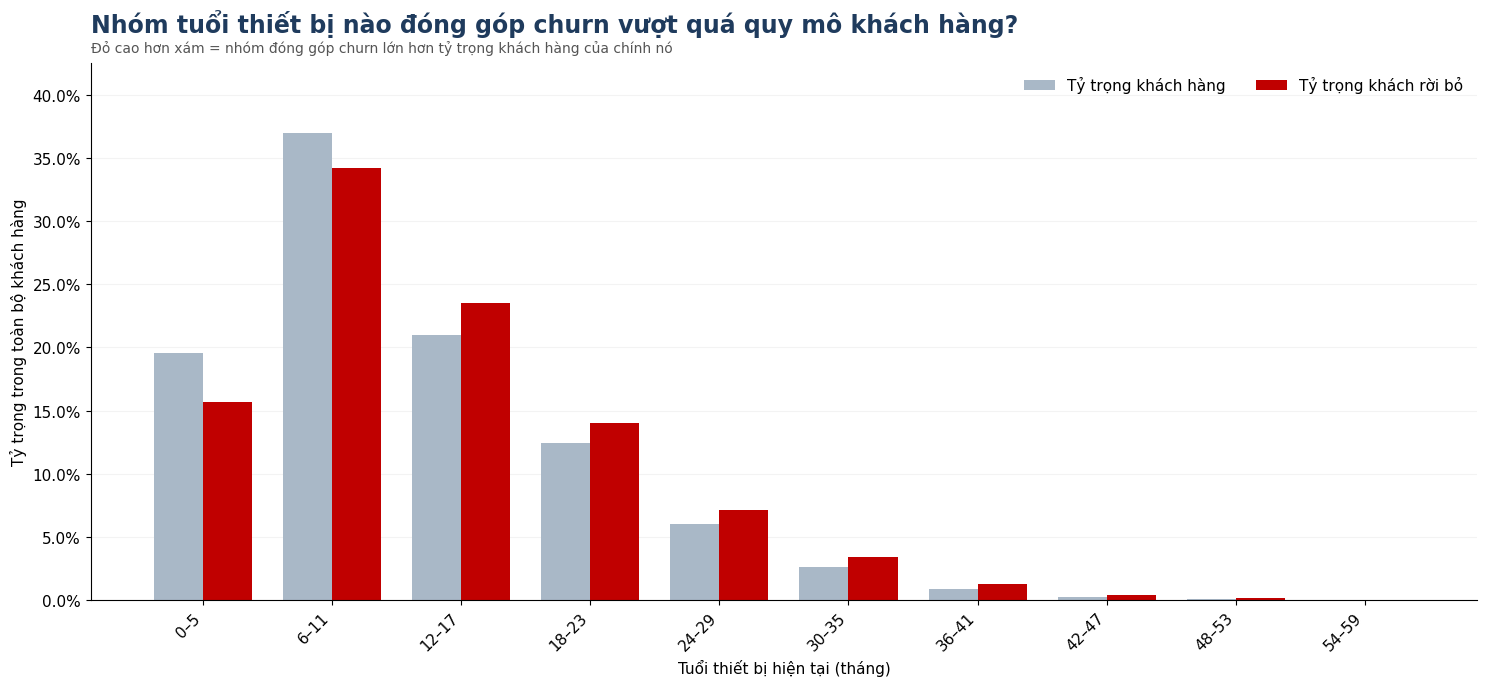

In [9]:
x = np.arange(len(concentration_6m))
width = 0.38

fig, ax = plt.subplots(figsize=(15, 7))

ax.bar(
    x - width / 2,
    concentration_6m["customer_share"],
    width,
    color="#A9B8C7",
    label="Tỷ trọng khách hàng"
)

ax.bar(
    x + width / 2,
    concentration_6m["churn_share"],
    width,
    color="#C00000",
    label="Tỷ trọng khách rời bỏ"
)

ax.set_title(
    "Nhóm tuổi thiết bị nào đóng góp churn vượt quá quy mô khách hàng?",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#1F3B5D",
    pad=22
)

ax.text(
    0,
    1.02,
    (
        "Đỏ cao hơn xám = nhóm đóng góp churn lớn hơn "
        "tỷ trọng khách hàng của chính nó"
    ),
    transform=ax.transAxes,
    fontsize=10,
    color="#555555"
)

ax.set_xlabel("Tuổi thiết bị hiện tại (tháng)")
ax.set_ylabel("Tỷ trọng trong toàn bộ khách hàng")

ax.set_xticks(x)
ax.set_xticklabels(
    concentration_6m["EquipmentAgeBand"],
    rotation=45,
    ha="right"
)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set_ylim(
    0,
    max(
        concentration_6m[
            ["customer_share", "churn_share"]
        ].max().max() * 1.15,
        0.01
    )
)

ax.margins(y=0)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    ncol=2,
    loc="upper right"
)

plt.tight_layout()
plt.show()


## 6. Chỉ số tập trung churn

\[
Chỉ\ số\ tập\ trung =

rac{Tỷ\ trọng\ khách\ rời\ bỏ}
{Tỷ\ trọng\ khách\ hàng}
\]

- `> 1`: đóng góp churn vượt quy mô.
- `≈ 1`: churn tương xứng với quy mô.
- `< 1`: đóng góp churn thấp hơn quy mô.

Luôn đọc chỉ số này cùng với số khách hàng và số churn thực tế để tránh ưu tiên một nhóm quá nhỏ.

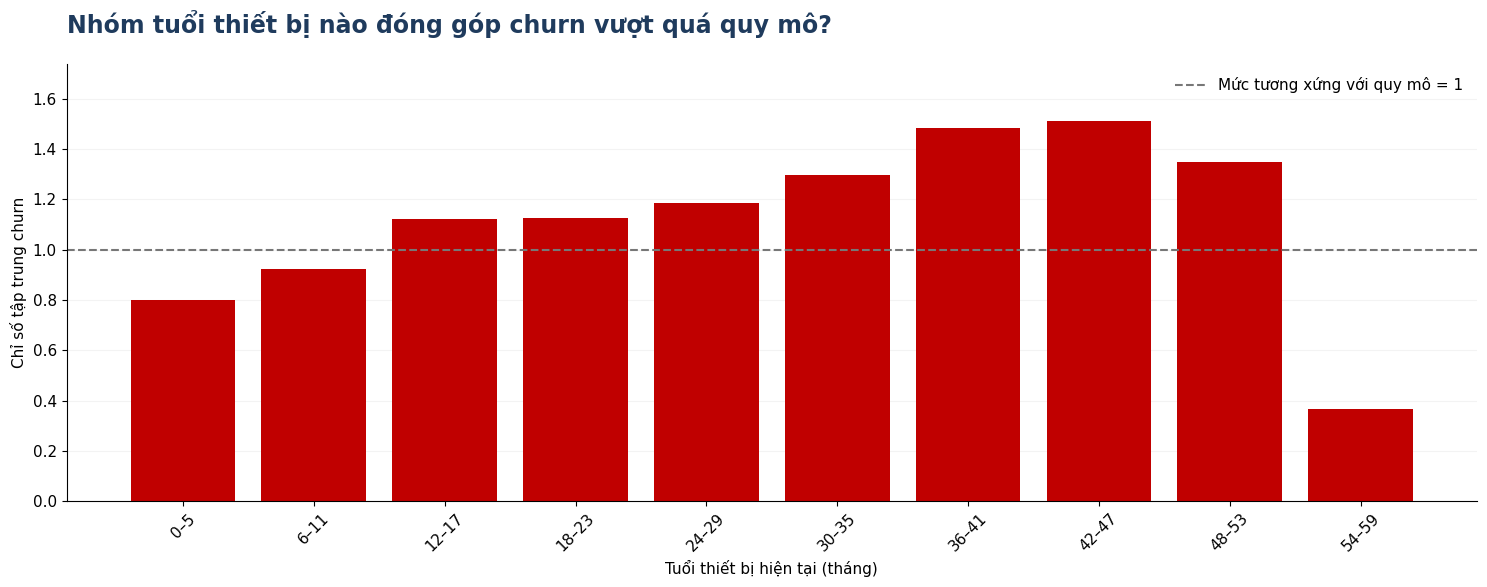

In [10]:
fig, ax = plt.subplots(figsize=(15, 6))

bars = ax.bar(
    concentration_6m["EquipmentAgeBand"].astype(str),
    concentration_6m["concentration_index"],
    color="#C00000"
)

ax.axhline(
    1,
    linestyle="--",
    linewidth=1.5,
    color="#777777",
    label="Mức tương xứng với quy mô = 1"
)

ax.set_title(
    "Nhóm tuổi thiết bị nào đóng góp churn vượt quá quy mô?",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#1F3B5D",
    pad=22
)

ax.set_xlabel("Tuổi thiết bị hiện tại (tháng)")
ax.set_ylabel("Chỉ số tập trung churn")

ax.set_ylim(
    0,
    max(
        concentration_6m["concentration_index"].max() * 1.15,
        1.2
    )
)

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()


## 7. Phân biệt nhóm có nhiều churn và nhóm thực sự vượt quy mô

Hai câu hỏi này khác nhau:

1. **Nhóm nào chứa nhiều khách rời bỏ nhất?**
2. **Nhóm nào có tỷ trọng churn cao hơn tỷ trọng khách hàng của chính nó?**

Một nhóm có nhiều churner chỉ vì nhóm đó rất đông chưa chắc là nhóm cần ưu tiên nhất.

In [ ]:
top_churn_share = (
    concentration_6m
    .sort_values(
        "churn_share",
        ascending=False
    )
    .head(10)
)

top_over_index = (
    concentration_6m
    .sort_values(
        "concentration_index",
        ascending=False
    )
    .head(10)
)

print("Xếp hạng theo tỷ trọng khách rời bỏ:")
display(
    top_churn_share[
        [
            "EquipmentAgeBand",
            "n",
            "churn_count",
            "customer_share",
            "churn_share",
            "concentration_index"
        ]
    ]
)

print("\nXếp hạng theo chỉ số tập trung churn:")
display(
    top_over_index[
        [
            "EquipmentAgeBand",
            "n",
            "churn_count",
            "customer_share",
            "churn_share",
            "concentration_index"
        ]
    ]
)


Xếp hạng theo tỷ trọng khách rời bỏ:


,EquipmentAgeBand,n,churn_count,customer_share,churn_share,concentration_index
1,6–11,18377,4872,0.369922,0.342351,0.925468
2,12–17,10410,3352,0.209549,0.235542,1.124041
0,0–5,9721,2230,0.195680,0.156700,0.800797
3,18–23,6199,1998,0.124784,0.140398,1.125130
4,24–29,3007,1021,0.060530,0.071745,1.185280
5,30–35,1300,483,0.026169,0.033940,1.296978
6,36–41,445,189,0.008958,0.013281,1.482622
7,42–47,143,62,0.002879,0.004357,1.513507
8,48–53,57,22,0.001147,0.001546,1.347338
9,54–59,19,2,0.000382,0.000141,0.367456



Xếp hạng theo chỉ số tập trung churn:


,EquipmentAgeBand,n,churn_count,customer_share,churn_share,concentration_index
7,42–47,143,62,0.002879,0.004357,1.513507
6,36–41,445,189,0.008958,0.013281,1.482622
8,48–53,57,22,0.001147,0.001546,1.347338
5,30–35,1300,483,0.026169,0.033940,1.296978
4,24–29,3007,1021,0.060530,0.071745,1.185280
3,18–23,6199,1998,0.124784,0.140398,1.125130
2,12–17,10410,3352,0.209549,0.235542,1.124041
1,6–11,18377,4872,0.369922,0.342351,0.925468
0,0–5,9721,2230,0.195680,0.156700,0.800797
9,54–59,19,2,0.000382,0.000141,0.367456


## 8. Kiểm tra độ nhạy khi thay đổi độ rộng khoảng tuổi thiết bị

So sánh kết quả khi chia tuổi thiết bị theo:

- 3 tháng;
- 6 tháng;
- 12 tháng.

Không yêu cầu các mốc phải giống nhau hoàn toàn. Mục tiêu là kiểm tra xem **vùng tuổi thiết bị đóng góp churn vượt quy mô có giữ cùng xu hướng hay không**.

In [ ]:
sensitivity_summaries = {}

for width in [3, 6, 12]:
    _, summary = make_fixed_width_summary(
        bq06_valid,
        width_months=width
    )

    sensitivity_summaries[width] = summary

    print(
        f"\n5 nhóm có chỉ số tập trung churn cao nhất — khoảng {width} tháng"
    )

    display(
        summary.nlargest(
            5,
            "concentration_index"
        )[
            [
                "EquipmentAgeBand",
                "n",
                "churn_count",
                "customer_share",
                "churn_share",
                "concentration_index"
            ]
        ]
    )



5 nhóm có chỉ số tập trung churn cao nhất — khoảng 3 tháng


,EquipmentAgeBand,n,churn_count,customer_share,churn_share,concentration_index
16,48–50,24,12,0.000483,0.000843,1.745415
14,42–44,93,41,0.001872,0.002881,1.538968
13,39–41,147,64,0.002959,0.004497,1.519817
15,45–47,50,21,0.001006,0.001476,1.466149
12,36–38,298,125,0.005999,0.008784,1.464274



5 nhóm có chỉ số tập trung churn cao nhất — khoảng 6 tháng


,EquipmentAgeBand,n,churn_count,customer_share,churn_share,concentration_index
7,42–47,143,62,0.002879,0.004357,1.513507
6,36–41,445,189,0.008958,0.013281,1.482622
8,48–53,57,22,0.001147,0.001546,1.347338
5,30–35,1300,483,0.026169,0.033940,1.296978
4,24–29,3007,1021,0.060530,0.071745,1.185280



5 nhóm có chỉ số tập trung churn cao nhất — khoảng 12 tháng


,EquipmentAgeBand,n,churn_count,customer_share,churn_share,concentration_index
3,36–47,588,251,0.011836,0.017638,1.490133
2,24–35,4307,1504,0.086698,0.105685,1.218994
1,12–23,16609,5350,0.334333,0.375940,1.124447
4,48–59,76,24,0.001530,0.001686,1.102367
0,0–11,28098,7102,0.565602,0.499051,0.882336


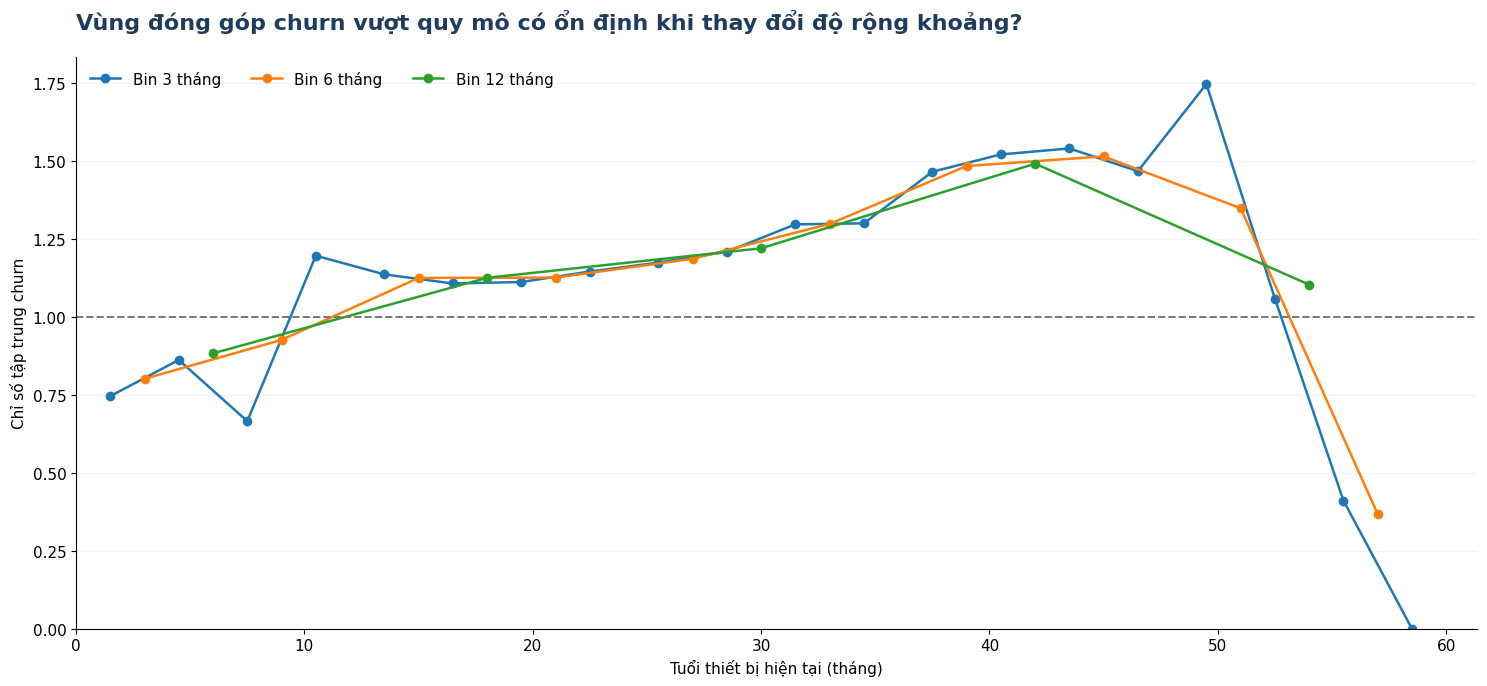

In [ ]:
fig, ax = plt.subplots(figsize=(15, 7))

for width in [3, 6, 12]:
    s = sensitivity_summaries[width].copy()

    # Midpoint chỉ để đặt các bin trên cùng một trục tuổi thiết bị
    left_edges = (
        s["EquipmentAgeBand"]
        .astype(str)
        .str.split("–")
        .str[0]
        .astype(float)
    )

    midpoints = left_edges + width / 2

    ax.plot(
        midpoints,
        s["concentration_index"],
        marker="o",
        linewidth=1.8,
        label=f"Bin {width} tháng"
    )

ax.axhline(
    1,
    linestyle="--",
    linewidth=1.4,
    color="#777777"
)

ax.set_title(
    "Vùng đóng góp churn vượt quy mô có ổn định khi thay đổi độ rộng khoảng?",
    loc="left",
    fontsize=16,
    fontweight="bold",
    color="#1F3B5D",
    pad=20
)

ax.set_xlabel("Tuổi thiết bị hiện tại (tháng)")
ax.set_ylabel("Chỉ số tập trung churn")

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    ncol=3
)

plt.tight_layout()
plt.show()


## 9. Kiểm tra độ nhạy bằng các nhóm phân vị

Các khoảng có độ rộng cố định dễ hiểu nhưng có thể có quy mô khách hàng rất khác nhau.

Phân tích phân vị chia khách hàng thành các nhóm có số lượng gần cân bằng hơn, giúp kiểm tra xem kết luận có còn giữ được khi thay đổi cách chia nhóm hay không.

In [ ]:
q_df = bq06_valid.copy()

q_df["EquipmentAgeQuantile"] = pd.qcut(
    q_df["CurrentEquipmentDays"],
    q=5,
    duplicates="drop"
)

q_summary = (
    q_df
    .groupby(
        "EquipmentAgeQuantile",
        observed=False
    )
    .agg(
        n=("Churn_bin", "size"),
        churn_count=("Churn_bin", "sum"),
        median_equipment_days=(
            "CurrentEquipmentDays",
            "median"
        )
    )
    .reset_index()
)

q_summary["customer_share"] = (
    q_summary["n"]
    / q_summary["n"].sum()
)

q_summary["churn_share"] = (
    q_summary["churn_count"]
    / q_summary["churn_count"].sum()
)

q_summary["concentration_index"] = (
    q_summary["churn_share"]
    / q_summary["customer_share"]
)

q_summary["median_equipment_months"] = (
    q_summary["median_equipment_days"]
    / AVG_DAYS_PER_MONTH
)

display(q_summary)


,EquipmentAgeQuantile,n,churn_count,median_equipment_days,customer_share,churn_share,concentration_index,median_equipment_months
0,"(-0.001, 184.0]",9992,2279,90.0,0.201135,0.160143,0.796197,2.956879
1,"(184.0, 283.0]",9928,1891,230.0,0.199847,0.132879,0.664903,7.556468
2,"(283.0, 384.0]",9929,3501,330.0,0.199867,0.246012,1.230879,10.841889
3,"(384.0, 575.6]",9893,3186,463.0,0.199142,0.223877,1.124207,15.211499
4,"(575.6, 1812.0]",9936,3374,731.0,0.200008,0.237088,1.185393,24.016427


## 10. Kiểm tra ảnh hưởng của thời gian sử dụng dịch vụ

Khách hàng sử dụng dịch vụ lâu hơn có thể đồng thời sở hữu thiết bị lâu hơn. Vì vậy cần kiểm tra xem mức tập trung churn theo tuổi thiết bị có chỉ do cơ cấu `MonthsInService` hay không.

Cách làm:

1. Chia `MonthsInService` thành 4 lớp theo tứ phân vị.
2. Trong mỗi lớp, tính số churn kỳ vọng của từng nhóm tuổi thiết bị nếu nhóm đó chỉ mang mức churn chung của lớp thời gian sử dụng.
3. Cộng số churn kỳ vọng qua các lớp.
4. Tính:

\[
O/E = \frac{Churn\ quan\ sát}{Churn\ kỳ\ vọng\ sau\ khi\ xét\ thời\ gian\ sử\ dụng}
\]

Cách đọc:

- `O/E > 1`: churn quan sát cao hơn kỳ vọng ngay cả sau khi xét thời gian sử dụng.
- `O/E ≈ 1`: mức tập trung ban đầu có thể chủ yếu do cơ cấu thời gian sử dụng.
- `O/E < 1`: churn quan sát thấp hơn kỳ vọng.

Đây vẫn là điều chỉnh mô tả, không phải bằng chứng nhân quả.

In [ ]:
tenure_df = bq06_6m.copy()

tenure_df["TenureStratum"] = pd.qcut(
    tenure_df["MonthsInService"],
    q=4,
    duplicates="drop"
)

# Churn propensity chung của từng tenure stratum
tenure_stratum_stats = (
    tenure_df
    .groupby(
        "TenureStratum",
        observed=False
    )
    .agg(
        stratum_n=("Churn_bin", "size"),
        stratum_churn=("Churn_bin", "sum")
    )
    .reset_index()
)

tenure_stratum_stats["stratum_churn_propensity"] = (
    tenure_stratum_stats["stratum_churn"]
    / tenure_stratum_stats["stratum_n"]
)

# Quy mô từng equipment-age band bên trong từng tenure stratum
age_tenure_cells = (
    tenure_df
    .groupby(
        [
            "EquipmentAgeBand",
            "TenureStratum"
        ],
        observed=False
    )
    .agg(
        n=("Churn_bin", "size"),
        observed_churn=("Churn_bin", "sum")
    )
    .reset_index()
)

age_tenure_cells = age_tenure_cells.merge(
    tenure_stratum_stats[
        [
            "TenureStratum",
            "stratum_churn_propensity"
        ]
    ],
    on="TenureStratum",
    how="left"
)

age_tenure_cells["expected_churn_given_tenure"] = (
    age_tenure_cells["n"]
    * age_tenure_cells["stratum_churn_propensity"]
)

tenure_adjusted = (
    age_tenure_cells
    .groupby(
        "EquipmentAgeBand",
        observed=False
    )
    .agg(
        n=("n", "sum"),
        observed_churn=("observed_churn", "sum"),
        expected_churn_given_tenure=(
            "expected_churn_given_tenure",
            "sum"
        )
    )
    .reset_index()
)

tenure_adjusted = tenure_adjusted.loc[
    tenure_adjusted["n"] > 0
].copy()

tenure_adjusted["tenure_adjusted_OE"] = (
    tenure_adjusted["observed_churn"]
    / tenure_adjusted["expected_churn_given_tenure"]
)

display(tenure_adjusted)


,EquipmentAgeBand,n,observed_churn,expected_churn_given_tenure,tenure_adjusted_OE
0,0–5,9721,2230,2802.199346,0.795803
1,6–11,18377,4872,4885.441215,0.997249
2,12–17,10410,3352,3319.381929,1.009827
3,18–23,6199,1998,1820.163540,1.097704
4,24–29,3007,1021,849.828197,1.201419
5,30–35,1300,483,366.691195,1.317185
6,36–41,445,189,125.521217,1.505722
7,42–47,143,62,40.336031,1.537087
8,48–53,57,22,16.077999,1.368330
9,54–59,19,2,5.359333,0.373181


,EquipmentAgeBand,n,churn_count,customer_share,churn_share,concentration_index,expected_churn_given_tenure,tenure_adjusted_OE
0,0–5,9721,2230,0.195680,0.156700,0.800797,2802.199346,0.795803
1,6–11,18377,4872,0.369922,0.342351,0.925468,4885.441215,0.997249
2,12–17,10410,3352,0.209549,0.235542,1.124041,3319.381929,1.009827
3,18–23,6199,1998,0.124784,0.140398,1.125130,1820.163540,1.097704
4,24–29,3007,1021,0.060530,0.071745,1.185280,849.828197,1.201419
5,30–35,1300,483,0.026169,0.033940,1.296978,366.691195,1.317185
6,36–41,445,189,0.008958,0.013281,1.482622,125.521217,1.505722
7,42–47,143,62,0.002879,0.004357,1.513507,40.336031,1.537087
8,48–53,57,22,0.001147,0.001546,1.347338,16.077999,1.368330
9,54–59,19,2,0.000382,0.000141,0.367456,5.359333,0.373181


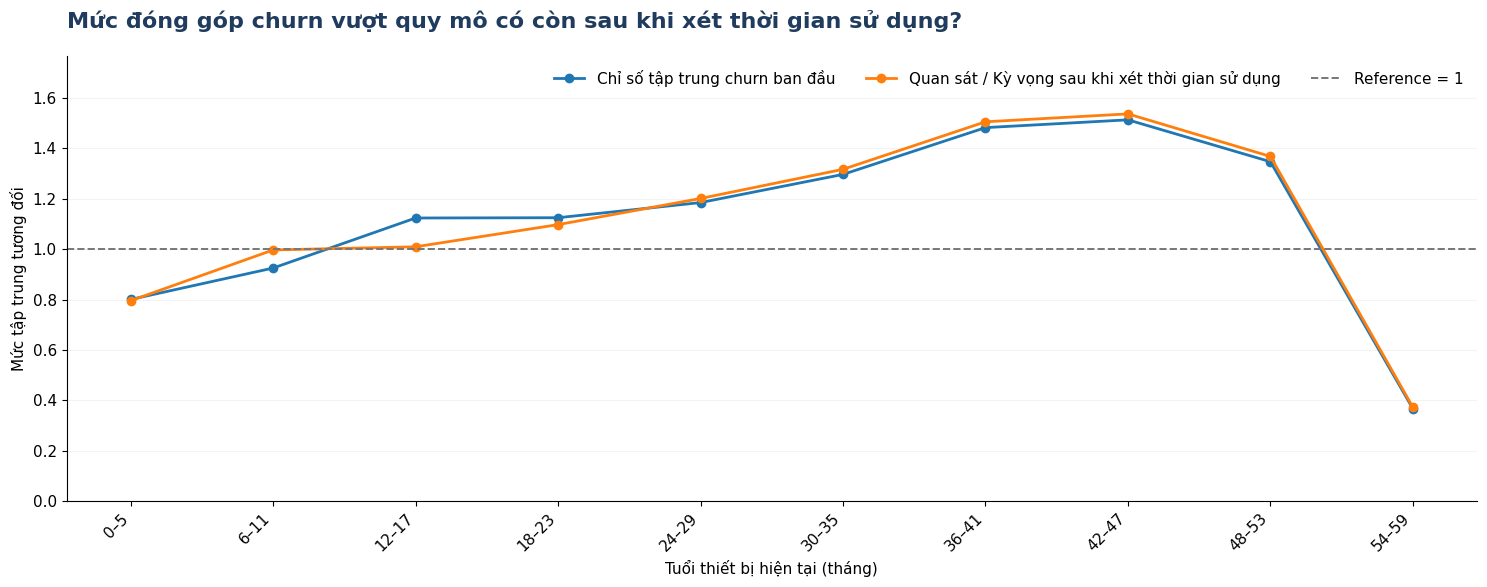

In [ ]:
comparison = concentration_6m[
    [
        "EquipmentAgeBand",
        "n",
        "churn_count",
        "customer_share",
        "churn_share",
        "concentration_index"
    ]
].merge(
    tenure_adjusted[
        [
            "EquipmentAgeBand",
            "expected_churn_given_tenure",
            "tenure_adjusted_OE"
        ]
    ],
    on="EquipmentAgeBand",
    how="left"
)

display(comparison)

fig, ax = plt.subplots(figsize=(15, 6))

x = np.arange(len(comparison))

ax.plot(
    x,
    comparison["concentration_index"],
    marker="o",
    linewidth=2,
    label="Chỉ số tập trung churn ban đầu"
)

ax.plot(
    x,
    comparison["tenure_adjusted_OE"],
    marker="o",
    linewidth=2,
    label="Quan sát / Kỳ vọng sau khi xét thời gian sử dụng"
)

ax.axhline(
    1,
    linestyle="--",
    linewidth=1.4,
    color="#777777",
    label="Reference = 1"
)

ax.set_title(
    "Mức đóng góp churn vượt quy mô có còn sau khi xét thời gian sử dụng?",
    loc="left",
    fontsize=16,
    fontweight="bold",
    color="#1F3B5D",
    pad=20
)

ax.set_xlabel("Tuổi thiết bị hiện tại (tháng)")
ax.set_ylabel("Mức tập trung tương đối")

ax.set_xticks(x)
ax.set_xticklabels(
    comparison["EquipmentAgeBand"],
    rotation=45,
    ha="right"
)

ax.set_ylim(
    0,
    max(
        comparison[
            [
                "concentration_index",
                "tenure_adjusted_OE"
            ]
        ].max().max() * 1.15,
        1.2
    )
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    ncol=3
)

plt.tight_layout()
plt.show()


## 11. Quy tắc kết luận BQ06

### Mức **Quan sát được**

Có thể kết luận:

> Khách rời bỏ tập trung nhiều hơn ở một số vùng tuổi thiết bị; những vùng có tỷ trọng churn lớn hơn tỷ trọng khách hàng đang đóng góp churn vượt quy mô của chính nhóm đó.

### Nâng lên mức **Được hỗ trợ** khi

- vùng nổi bật giữ cùng xu hướng khi dùng khoảng 3 / 6 / 12 tháng;
- kết quả theo phân vị cho cùng câu chuyện tổng quát;
- `O/E` sau khi xét thời gian sử dụng vẫn lớn hơn 1;
- nhóm có đủ số khách và số churn để có ý nghĩa vận hành.

### Hàm ý giữ chân khách hàng

Nếu một vùng tuổi thiết bị:

- có nhiều churner;
- chỉ số tập trung > 1;
- vẫn có `O/E > 1` sau khi xét thời gian sử dụng;
- và quy mô đủ lớn;

thì đưa nhóm đó sang **BQ07** để kiểm tra thêm `HandsetWebCapable` trước khi cân nhắc thử nghiệm rà soát hoặc nâng cấp thiết bị.

### Không được kết luận

- Thiết bị cũ **gây ra** churn.
- Đổi thiết bị chắc chắn **làm giảm** churn.
- Một ngưỡng tuổi thiết bị là ngưỡng chính sách tối ưu chỉ vì chỉ số tập trung cao.

Nâng cấp thiết bị vẫn chỉ là một giả thuyết can thiệp cần kiểm chứng ở các bước chính sách và thử nghiệm sau.

## 12. Đầu ra tối thiểu đưa vào báo cáo

Giữ 3 đầu ra chính:

1. **Biểu đồ phân phối xếp chồng** — churn tập trung ở vùng tuổi thiết bị nào.
2. **Tỷ trọng khách hàng so với tỷ trọng khách rời bỏ** — nhóm nào đóng góp churn vượt quy mô.
3. **Chỉ số tập trung ban đầu so với O/E sau khi xét thời gian sử dụng** — mức tập trung có còn sau điều chỉnh hay không.

Các bảng kiểm tra độ nhạy để trong notebook hoặc phụ lục.